Sift with Blending

── Initializing SIFT ──

[PHASE 1] ── STEP 1: Extracting & Visualizing SIFT (pt2 & pt1) ──


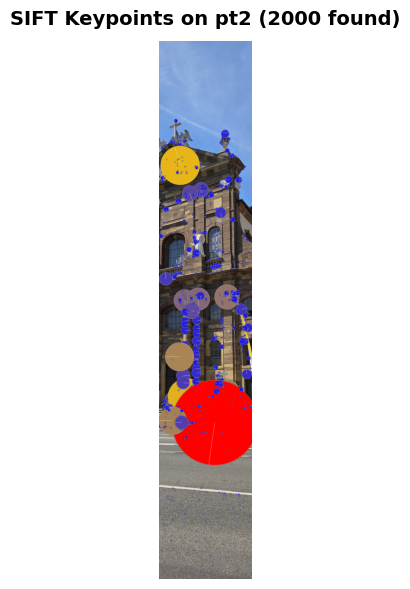

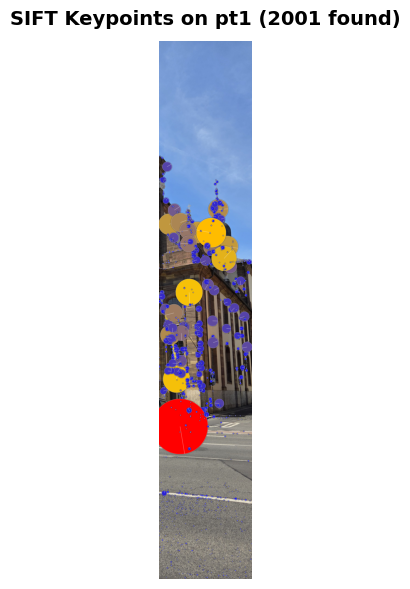


[PHASE 1] ── STEP 2: KNN Matches (Lowe's Ratio applied) ──
Good matches between pt2 and pt1: 162


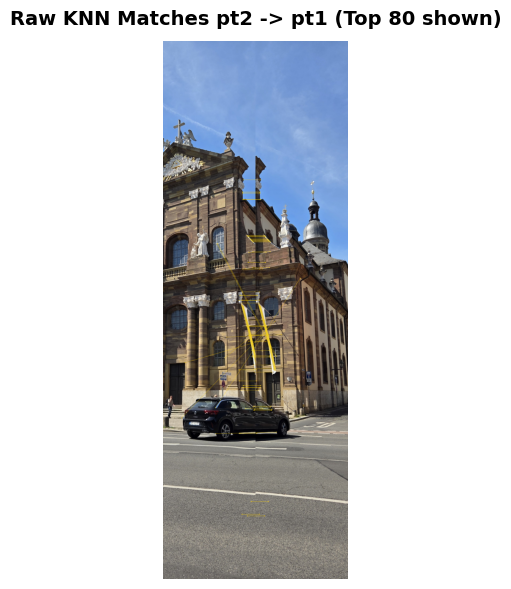


[PHASE 1] ── STEP 3: RANSAC Inliers ──


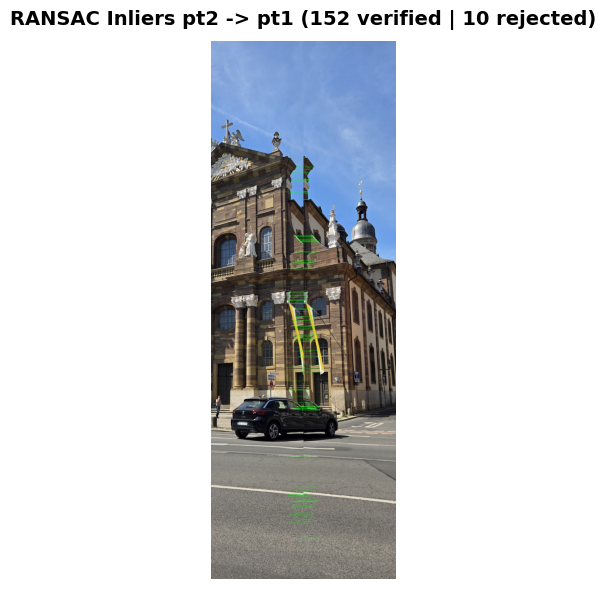


[PHASE 1] ── STEP 4: Stitching pt2 + pt1 ──


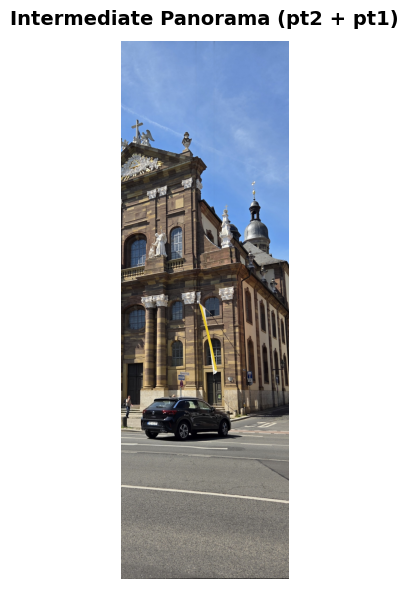


[PHASE 2] ── STEP 5: SIFT on Intermediate Panorama & pt3 ──


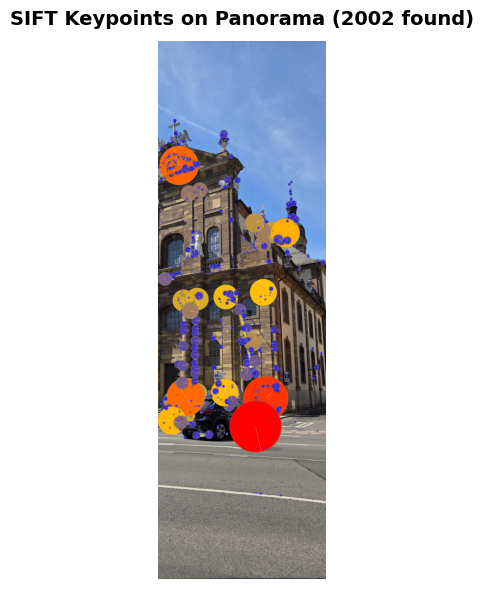

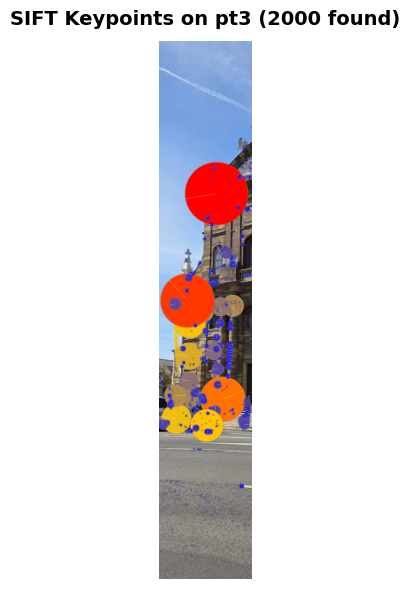


[PHASE 2] ── STEP 6: KNN Matches (pt3 -> Panorama) ──
Good matches between pt3 and panorama: 154


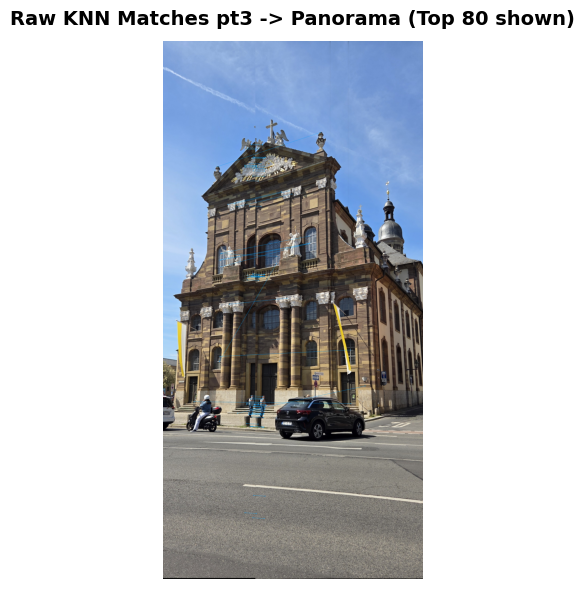


[PHASE 2] ── STEP 7: RANSAC Inliers (pt3 -> Panorama) ──


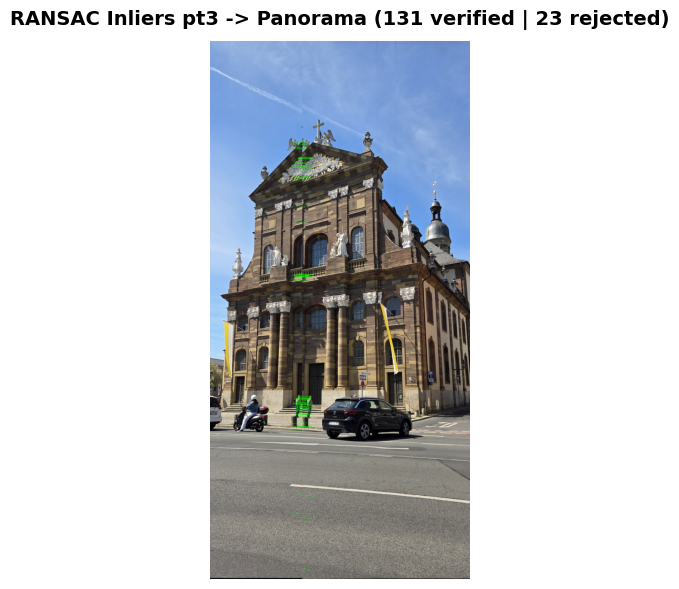


[PHASE 2] ── STEP 8: Final Stitch & Blend ──

✓ Pipeline complete! Displaying and saving...


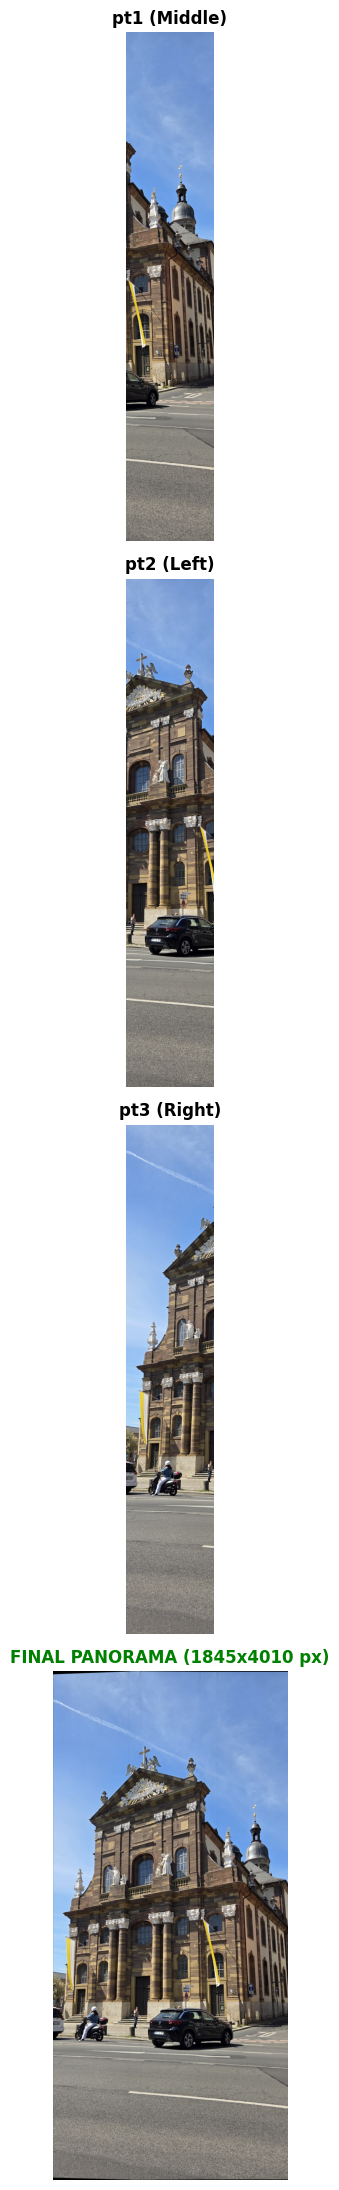

Saved successfully to: C:\Users\USER\OneDrive - GJU\Desktop\4th Year\MI 2\Homeworks\final_stitched_panorama.jpg


In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ─────────────────────────────────────────────────────────────────────────────
# 1. HELPERS & VISUALIZATION TOOLS
# ─────────────────────────────────────────────────────────────────────────────
def show(img_bgr, title="", figsize=(18, 6)):
    """Helper to display BGR images correctly in Matplotlib."""
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    plt.title(title, fontsize=14, fontweight="bold", pad=12)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

def resize_to(img, max_w=1200):
    """Resizes large images to prevent memory crashes."""
    h, w = img.shape[:2]
    if w > max_w:
        img = cv2.resize(img, (max_w, int(h * max_w / w)))
    return img

def draw_fancy_keypoints(img, keypoints):
    """Draws keypoints with a color ramp based on scale size and shows orientation."""
    out = img.copy()
    sizes = np.array([k.size for k in keypoints])
    if len(sizes) == 0: return out
    s_min, s_max = sizes.min(), sizes.max() + 1e-6

    for kp in keypoints:
        x, y   = int(kp.pt[0]), int(kp.pt[1])
        radius = max(3, int(kp.size * 1.5))
        t      = (kp.size - s_min) / (s_max - s_min)

        # Color ramp: Blue (small) -> Yellow -> Red (large)
        if t < 0.5:
            r, g, b = int(255 * t * 2), int(200 * t * 2), int(255 * (1 - t * 2))
        else:
            r, g, b = 255, int(200 * (1 - (t - 0.5) * 2)), 0

        cv2.circle(out, (x, y), radius, (b, g, r), -1)
        cv2.circle(out, (x, y), radius, (255, 255, 255), 1)
        cv2.circle(out, (x, y), radius + 2, (0, 0, 0), 1)

        if kp.angle >= 0:
            angle_rad = np.deg2rad(kp.angle)
            ex = int(x + radius * np.cos(angle_rad))
            ey = int(y + radius * np.sin(angle_rad))
            cv2.line(out, (x, y), (ex, ey), (255, 255, 255), 1, cv2.LINE_AA)
    return out

# ─────────────────────────────────────────────────────────────────────────────
# 2. CORE PIPELINE FUNCTIONS
# ─────────────────────────────────────────────────────────────────────────────
def make_sift():
    # Rely on defaults for quality points, capped at 2000 to prevent noise
    return cv2.SIFT_create(nfeatures=2000)

def get_good_matches(des_query, des_train):
    flann = cv2.FlannBasedMatcher(dict(algorithm=1, trees=12), dict(checks=150))
    raw = flann.knnMatch(des_query, des_train, k=2)
    
    # Tightened Lowe's ratio to 0.65 to reject repetitive building textures
    good_matches = []
    for match in raw:
        if len(match) == 2:
            m, n = match
            if m.distance < 0.65 * n.distance:
                good_matches.append(m)
    return good_matches

def compute_homography(kp_query, kp_train, matches):
    pts_query = np.float32([kp_query[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
    pts_train = np.float32([kp_train[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(pts_query, pts_train, cv2.RANSAC, 
                                 ransacReprojThreshold=3.0, 
                                 confidence=0.999, maxIters=5000)
    return H, mask

def blend_pair(img_left, img_right, H):
    """Warps img_right into img_left space with auto-translation to prevent negative coordinate clipping."""
    h1, w1 = img_left.shape[:2]
    h2, w2 = img_right.shape[:2]

    # Calculate exact corners of warped image
    corners_right = np.float32([[0, 0], [0, h2], [w2, h2], [w2, 0]]).reshape(-1, 1, 2)
    warped_corners = cv2.perspectiveTransform(corners_right, H)
    corners_left = np.float32([[0, 0], [0, h1], [w1, h1], [w1, 0]]).reshape(-1, 1, 2)

    # Find the bounding box of the entire stitched panorama
    all_corners = np.concatenate((corners_left, warped_corners), axis=0)
    [x_min, y_min] = np.int32(all_corners.min(axis=0).ravel() - 0.5)
    [x_max, y_max] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

    # Translation Matrix to shift everything out of negative coordinates
    t_x = -x_min if x_min < 0 else 0
    t_y = -y_min if y_min < 0 else 0
    T = np.array([[1, 0, t_x], [0, 1, t_y], [0, 0, 1]], dtype=np.float32)

    H_trans = T.dot(H)
    nw, nh = x_max - x_min, y_max - y_min

    # Warp and shift onto safe canvas
    warped = cv2.warpPerspective(img_right, H_trans, (nw, nh))
    canvas = np.zeros((nh, nw, 3), dtype=np.uint8)
    canvas[t_y:t_y+h1, t_x:t_x+w1] = img_left

    # Create masks and calculate Distance Transform for feathering
    ml = np.zeros((nh, nw), dtype=np.uint8)
    ml[t_y:t_y+h1, t_x:t_x+w1] = 255
    mr = cv2.warpPerspective(np.ones((h2, w2), dtype=np.uint8) * 255, H_trans, (nw, nh))

    dl = cv2.GaussianBlur(cv2.distanceTransform(ml, cv2.DIST_L2, 3).astype(np.float32), (51, 51), 0)
    dr = cv2.GaussianBlur(cv2.distanceTransform(mr, cv2.DIST_L2, 3).astype(np.float32), (51, 51), 0)

    # Calculate alpha weights
    total = dl + dr + 1e-6
    al = (dl / total)[:, :, np.newaxis]
    ar = (dr / total)[:, :, np.newaxis]

    # Apply Feather Blending
    blended = np.clip(canvas.astype(np.float32)*al + warped.astype(np.float32)*ar, 0, 255).astype(np.uint8)

    # Crop black borders (Threshold increased to 15 to ignore floating-point noise)
    _, th = cv2.threshold(cv2.cvtColor(blended, cv2.COLOR_BGR2GRAY), 15, 255, cv2.THRESH_BINARY)
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        x, y, cw, ch = cv2.boundingRect(max(cnts, key=cv2.contourArea))
        blended = blended[y:y+ch, x:x+cw]
        
    return blended


# ─────────────────────────────────────────────────────────────────────────────
# 3. EXECUTION LOGIC WITH FULL STEP-BY-STEP VISUALIZATIONS
# ─────────────────────────────────────────────────────────────────────────────
import os
BASE = "inputs" if os.path.exists("inputs/pt1.jpg") else ("." if os.path.exists("pt1.jpg") else r"C:\Users\USER\OneDrive - GJU\Desktop\4th Year\MI 2\Homeworks")
part1 = resize_to(cv2.imread(BASE + r"\pt1.jpg"))  # Middle Image
part2 = resize_to(cv2.imread(BASE + r"\pt2.jpg"))  # Left Image
part3 = resize_to(cv2.imread(BASE + r"\pt3.jpg"))  # Right Image

if any(p is None for p in [part1, part2, part3]):
    raise FileNotFoundError("Could not load one or more images — check file paths.")

print("── Initializing SIFT ──")
sift = make_sift()

# ==========================================
# PHASE 1: Stitching pt2 (Left) to pt1 (Middle)
# ==========================================
print("\n[PHASE 1] ── STEP 1: Extracting & Visualizing SIFT (pt2 & pt1) ──")
gray1 = cv2.cvtColor(part1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(part2, cv2.COLOR_BGR2GRAY)

kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(gray2, None)

show(draw_fancy_keypoints(part2, kp2), f"SIFT Keypoints on pt2 ({len(kp2)} found)")
show(draw_fancy_keypoints(part1, kp1), f"SIFT Keypoints on pt1 ({len(kp1)} found)")

print("\n[PHASE 1] ── STEP 2: KNN Matches (Lowe's Ratio applied) ──")
# des2 is query (moving), des1 is train (anchor)
matches_21 = get_good_matches(des2, des1) 
print(f"Good matches between pt2 and pt1: {len(matches_21)}")

if len(matches_21) < 4:
    raise RuntimeError("Not enough matches to stitch pt2 and pt1.")

img_knn_21 = cv2.drawMatches(
    part2, kp2, part1, kp1, matches_21[:80], None,
    matchColor=(0, 210, 255), singlePointColor=(180, 80, 0),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
show(img_knn_21, f"Raw KNN Matches pt2 -> pt1 (Top 80 shown)")

print("\n[PHASE 1] ── STEP 3: RANSAC Inliers ──")
H21, mask21 = compute_homography(kp2, kp1, matches_21)

mask_list_21 = mask21.ravel().tolist()
inliers_21 = [matches_21[i] for i in range(len(matches_21)) if mask_list_21[i]]
outliers_count_21 = len(matches_21) - len(inliers_21)

img_ransac_21 = cv2.drawMatches(
    part2, kp2, part1, kp1, inliers_21, None,
    matchColor=(0, 255, 0), singlePointColor=(180, 80, 0),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
show(img_ransac_21, f"RANSAC Inliers pt2 -> pt1 ({len(inliers_21)} verified | {outliers_count_21} rejected)")

print("\n[PHASE 1] ── STEP 4: Stitching pt2 + pt1 ──")
stitch_21 = blend_pair(part1, part2, H21)
show(stitch_21, "Intermediate Panorama (pt2 + pt1)")


# ==========================================
# PHASE 2: Stitching pt3 (Right) to Panorama
# ==========================================
print("\n[PHASE 2] ── STEP 5: SIFT on Intermediate Panorama & pt3 ──")
gray_21 = cv2.cvtColor(stitch_21, cv2.COLOR_BGR2GRAY)
gray3 = cv2.cvtColor(part3, cv2.COLOR_BGR2GRAY)

kp_21, des_21 = sift.detectAndCompute(gray_21, None)
kp3, des3 = sift.detectAndCompute(gray3, None)

show(draw_fancy_keypoints(stitch_21, kp_21), f"SIFT Keypoints on Panorama ({len(kp_21)} found)")
show(draw_fancy_keypoints(part3, kp3), f"SIFT Keypoints on pt3 ({len(kp3)} found)")

print("\n[PHASE 2] ── STEP 6: KNN Matches (pt3 -> Panorama) ──")
matches_3_21 = get_good_matches(des3, des_21)
print(f"Good matches between pt3 and panorama: {len(matches_3_21)}")

if len(matches_3_21) < 4:
    raise RuntimeError("Not enough matches to add pt3 to the panorama.")

img_knn_3_21 = cv2.drawMatches(
    part3, kp3, stitch_21, kp_21, matches_3_21[:80], None,
    matchColor=(255, 160, 0), singlePointColor=(180, 80, 0),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
show(img_knn_3_21, "Raw KNN Matches pt3 -> Panorama (Top 80 shown)")

print("\n[PHASE 2] ── STEP 7: RANSAC Inliers (pt3 -> Panorama) ──")
H_3_21, mask_3_21 = compute_homography(kp3, kp_21, matches_3_21)

mask_list_3 = mask_3_21.ravel().tolist()
inliers_3_21 = [matches_3_21[i] for i in range(len(matches_3_21)) if mask_list_3[i]]
outliers_count_3 = len(matches_3_21) - len(inliers_3_21)

img_ransac_3_21 = cv2.drawMatches(
    part3, kp3, stitch_21, kp_21, inliers_3_21, None,
    matchColor=(0, 255, 0), singlePointColor=(180, 80, 0),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
show(img_ransac_3_21, f"RANSAC Inliers pt3 -> Panorama ({len(inliers_3_21)} verified | {outliers_count_3} rejected)")


print("\n[PHASE 2] ── STEP 8: Final Stitch & Blend ──")
final_panorama = blend_pair(stitch_21, part3, H_3_21)

# ─────────────────────────────────────────────────────────────────────────────
# 4. FINAL OUTPUT COMPARISON
# ─────────────────────────────────────────────────────────────────────────────
print("\n✓ Pipeline complete! Displaying and saving...")

fig, axes = plt.subplots(4, 1, figsize=(18, 22))
axes[0].imshow(cv2.cvtColor(part1, cv2.COLOR_BGR2RGB)); axes[0].set_title("pt1 (Middle)", fontweight="bold"); axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(part2, cv2.COLOR_BGR2RGB)); axes[1].set_title("pt2 (Left)", fontweight="bold"); axes[1].axis("off")
axes[2].imshow(cv2.cvtColor(part3, cv2.COLOR_BGR2RGB)); axes[2].set_title("pt3 (Right)", fontweight="bold"); axes[2].axis("off")
axes[3].imshow(cv2.cvtColor(final_panorama, cv2.COLOR_BGR2RGB)); axes[3].set_title(f"FINAL PANORAMA ({final_panorama.shape[1]}x{final_panorama.shape[0]} px)", color="green", fontweight="bold"); axes[3].axis("off")

plt.tight_layout()
plt.show()

# Save it to your folder
save_path = BASE + r"\final_stitched_panorama.jpg"
cv2.imwrite(save_path, final_panorama)
print(f"Saved successfully to: {save_path}")

ORB with bleinding

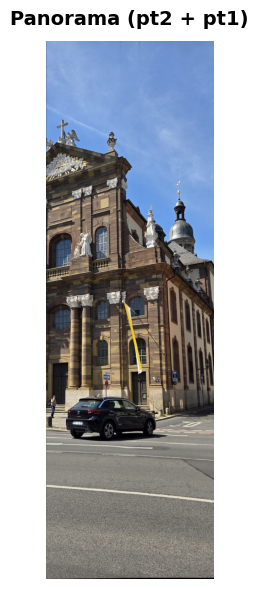

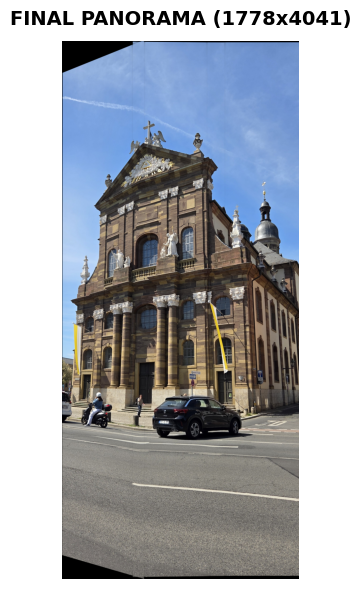

Saved to: C:\Users\USER\OneDrive - GJU\Desktop\4th Year\MI 2\Homeworks\final_panorama.jpg


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ─────────────────────────────────────────────────────────────────────────────
# 1. HELPERS & VISUALIZATION TOOLS
# ─────────────────────────────────────────────────────────────────────────────
def show(img_bgr, title="", figsize=(18, 6)):
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    plt.title(title, fontsize=14, fontweight="bold", pad=12)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

def resize_to(img, max_w=1200):
    h, w = img.shape[:2]
    if w > max_w:
        img = cv2.resize(img, (max_w, int(h * max_w / w)))
    return img

def draw_fancy_keypoints(img, keypoints):
    out = img.copy()
    sizes = np.array([k.size for k in keypoints])
    if len(sizes) == 0:
        return out

    s_min, s_max = sizes.min(), sizes.max() + 1e-6

    for kp in keypoints:
        x, y = int(kp.pt[0]), int(kp.pt[1])
        radius = max(3, int(kp.size * 1.5))
        t = (kp.size - s_min) / (s_max - s_min)

        if t < 0.5:
            r, g, b = int(255 * t * 2), int(200 * t * 2), int(255 * (1 - t * 2))
        else:
            r, g, b = 255, int(200 * (1 - (t - 0.5) * 2)), 0

        cv2.circle(out, (x, y), radius, (b, g, r), -1)
        cv2.circle(out, (x, y), radius, (255, 255, 255), 1)

        if kp.angle >= 0:
            angle_rad = np.deg2rad(kp.angle)
            ex = int(x + radius * np.cos(angle_rad))
            ey = int(y + radius * np.sin(angle_rad))
            cv2.line(out, (x, y), (ex, ey), (255, 255, 255), 1)

    return out

# ─────────────────────────────────────────────────────────────────────────────
# 2. ORB + MATCHING
# ─────────────────────────────────────────────────────────────────────────────
def make_ORB():
    return cv2.ORB_create(
        nfeatures=5000,
        scaleFactor=1.2,
        nlevels=8,
        edgeThreshold=15,
        patchSize=31
    )

def get_good_matches(des_query, des_train):
    if des_query is None or des_train is None:
        raise RuntimeError("Descriptor extraction failed.")

    bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)
    raw = bf.knnMatch(des_query, des_train, k=2)

    good = []
    for m, n in raw:
        if m.distance < 0.75 * n.distance:
            good.append(m)

    return good

# ─────────────────────────────────────────────────────────────────────────────
# 3. HOMOGRAPHY
# ─────────────────────────────────────────────────────────────────────────────
def compute_homography(kp_query, kp_train, matches):
    pts_query = np.float32([kp_query[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
    pts_train = np.float32([kp_train[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)

    H, mask = cv2.findHomography(
        pts_query, pts_train,
        cv2.RANSAC,
        ransacReprojThreshold=3.0,
        confidence=0.999,
        maxIters=5000
    )
    return H, mask

# ─────────────────────────────────────────────────────────────────────────────
# 4. BLENDING
# ─────────────────────────────────────────────────────────────────────────────
def blend_pair(img_left, img_right, H):
    h1, w1 = img_left.shape[:2]
    h2, w2 = img_right.shape[:2]

    corners_right = np.float32([[0,0],[0,h2],[w2,h2],[w2,0]]).reshape(-1,1,2)
    warped_corners = cv2.perspectiveTransform(corners_right, H)
    corners_left = np.float32([[0,0],[0,h1],[w1,h1],[w1,0]]).reshape(-1,1,2)

    all_corners = np.concatenate((corners_left, warped_corners), axis=0)
    [x_min, y_min] = np.int32(all_corners.min(axis=0).ravel() - 0.5)
    [x_max, y_max] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

    t_x = -x_min if x_min < 0 else 0
    t_y = -y_min if y_min < 0 else 0

    T = np.array([[1,0,t_x],[0,1,t_y],[0,0,1]], dtype=np.float32)
    H_trans = T.dot(H)

    nw, nh = x_max - x_min, y_max - y_min

    warped = cv2.warpPerspective(img_right, H_trans, (nw, nh))
    canvas = np.zeros((nh, nw, 3), dtype=np.uint8)
    canvas[t_y:t_y+h1, t_x:t_x+w1] = img_left

    # masks
    ml = np.zeros((nh, nw), dtype=np.uint8)
    ml[t_y:t_y+h1, t_x:t_x+w1] = 255
    mr = cv2.warpPerspective(np.ones((h2, w2), dtype=np.uint8)*255, H_trans, (nw, nh))

    dl = cv2.GaussianBlur(cv2.distanceTransform(ml, cv2.DIST_L2, 3), (51,51), 0)
    dr = cv2.GaussianBlur(cv2.distanceTransform(mr, cv2.DIST_L2, 3), (51,51), 0)

    total = dl + dr + 1e-6
    al = (dl / total)[:,:,None]
    ar = (dr / total)[:,:,None]

    blended = np.clip(canvas.astype(np.float32)*al + warped.astype(np.float32)*ar, 0,255).astype(np.uint8)

    # crop
    gray = cv2.cvtColor(blended, cv2.COLOR_BGR2GRAY)
    _, th = cv2.threshold(gray, 15, 255, cv2.THRESH_BINARY)
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if cnts:
        x,y,w,h = cv2.boundingRect(max(cnts, key=cv2.contourArea))
        blended = blended[y:y+h, x:x+w]

    return blended

# ─────────────────────────────────────────────────────────────────────────────
# 5. MAIN PIPELINE
# ─────────────────────────────────────────────────────────────────────────────
import os
BASE = "inputs" if os.path.exists("inputs/pt1.jpg") else ("." if os.path.exists("pt1.jpg") else r"C:\Users\USER\OneDrive - GJU\Desktop\4th Year\MI 2\Homeworks")

part1 = resize_to(cv2.imread(BASE + r"\pt1.jpg"))  # middle
part2 = resize_to(cv2.imread(BASE + r"\pt2.jpg"))  # left
part3 = resize_to(cv2.imread(BASE + r"\pt3.jpg"))  # right

if any(p is None for p in [part1, part2, part3]):
    raise FileNotFoundError("Check image paths")

orb = make_ORB()

# ───────── PHASE 1: pt2 → pt1 ─────────
gray1 = cv2.cvtColor(part1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(part2, cv2.COLOR_BGR2GRAY)

kp1, des1 = orb.detectAndCompute(gray1, None)
kp2, des2 = orb.detectAndCompute(gray2, None)

matches_21 = get_good_matches(des2, des1)

if len(matches_21) < 4:
    raise RuntimeError("Not enough matches")

H21, mask21 = compute_homography(kp2, kp1, matches_21)
stitch_21 = blend_pair(part1, part2, H21)

show(stitch_21, "Panorama (pt2 + pt1)")

# ───────── PHASE 2: pt3 → panorama ─────────
gray_21 = cv2.cvtColor(stitch_21, cv2.COLOR_BGR2GRAY)
gray3 = cv2.cvtColor(part3, cv2.COLOR_BGR2GRAY)

kp_21, des_21 = orb.detectAndCompute(gray_21, None)
kp3, des3 = orb.detectAndCompute(gray3, None)

matches_3 = get_good_matches(des3, des_21)

if len(matches_3) < 4:
    raise RuntimeError("Not enough matches")

H3, mask3 = compute_homography(kp3, kp_21, matches_3)
final_panorama = blend_pair(stitch_21, part3, H3)

# ───────────────── FINAL OUTPUT ─────────────────
show(final_panorama, f"FINAL ORB PANORAMA ({final_panorama.shape[1]}x{final_panorama.shape[0]})")

save_path = BASE + r"\final_panorama.jpg"
cv2.imwrite(save_path, final_panorama)

print("Saved to:", save_path)

Sift without blending

── Initializing SIFT ──

[PHASE 1] ── STEP 1: Extracting & Visualizing SIFT (pt2 & pt1) ──


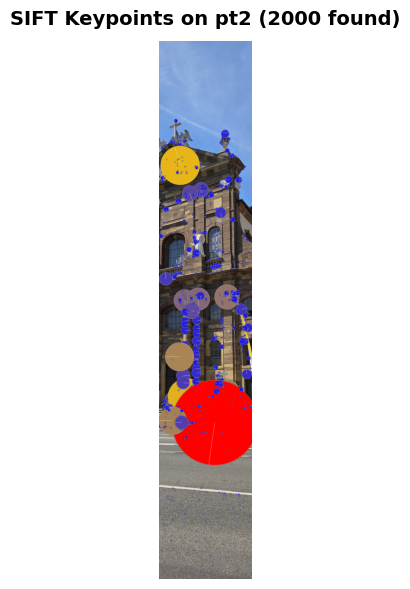

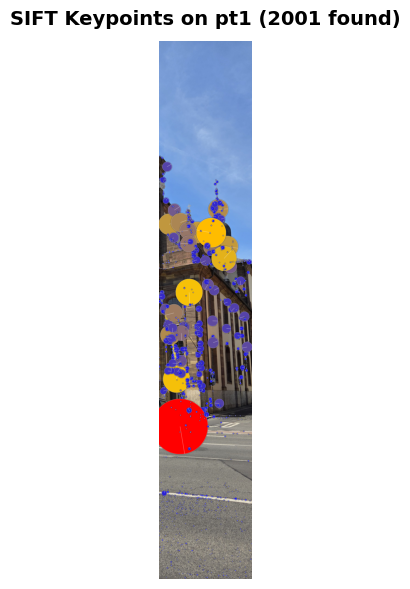


[PHASE 1] ── STEP 2: KNN Matches (Lowe's Ratio applied) ──
Good matches between pt2 and pt1: 162


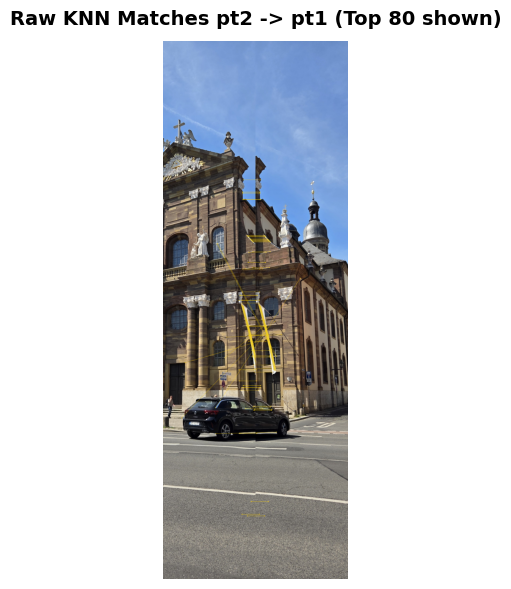


[PHASE 1] ── STEP 3: RANSAC Inliers ──


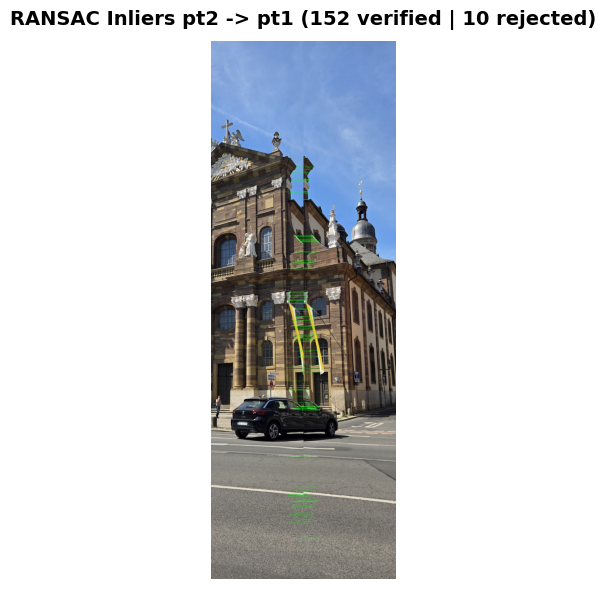


[PHASE 1] ── STEP 4: Stitching pt2 + pt1 (NO BLENDING) ──


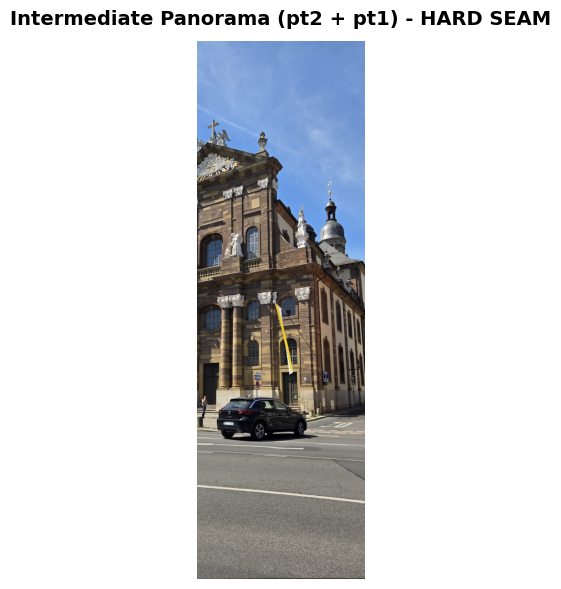


[PHASE 2] ── STEP 5: SIFT on Intermediate Panorama & pt3 ──


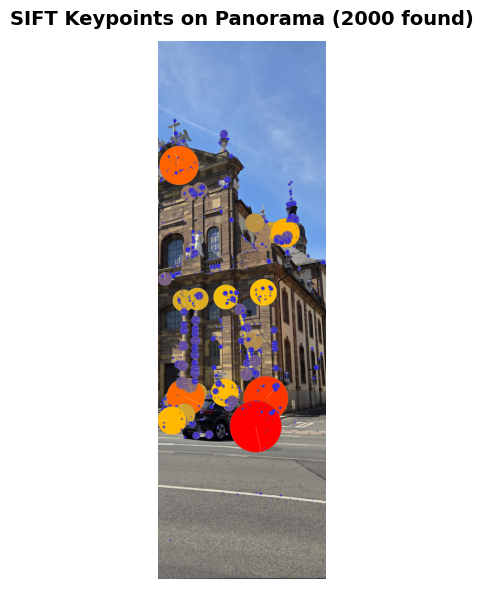

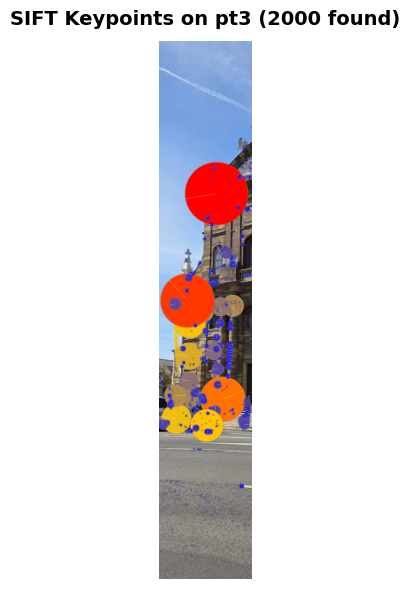


[PHASE 2] ── STEP 6: KNN Matches (pt3 -> Panorama) ──
Good matches between pt3 and panorama: 156


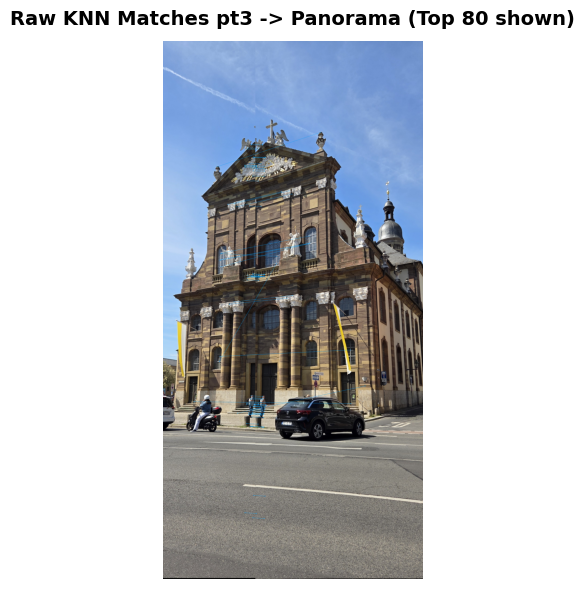


[PHASE 2] ── STEP 7: RANSAC Inliers (pt3 -> Panorama) ──


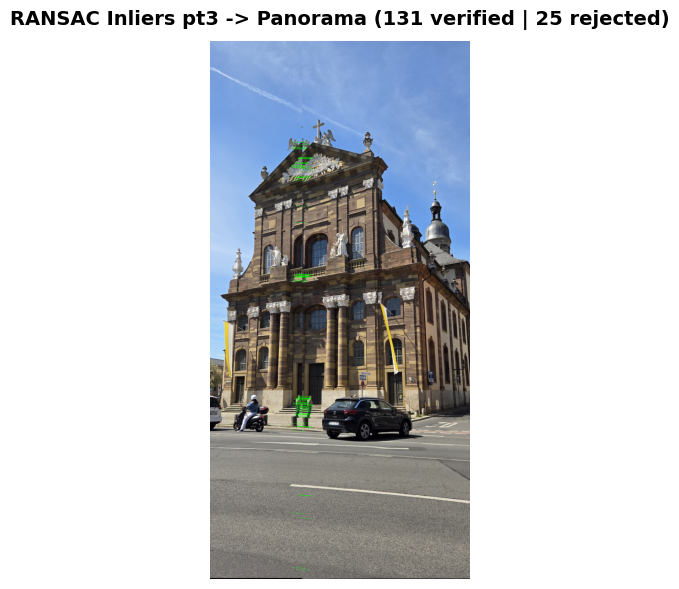


[PHASE 2] ── STEP 8: Final Stitch (NO BLENDING) ──

✓ Pipeline complete! Displaying and saving...


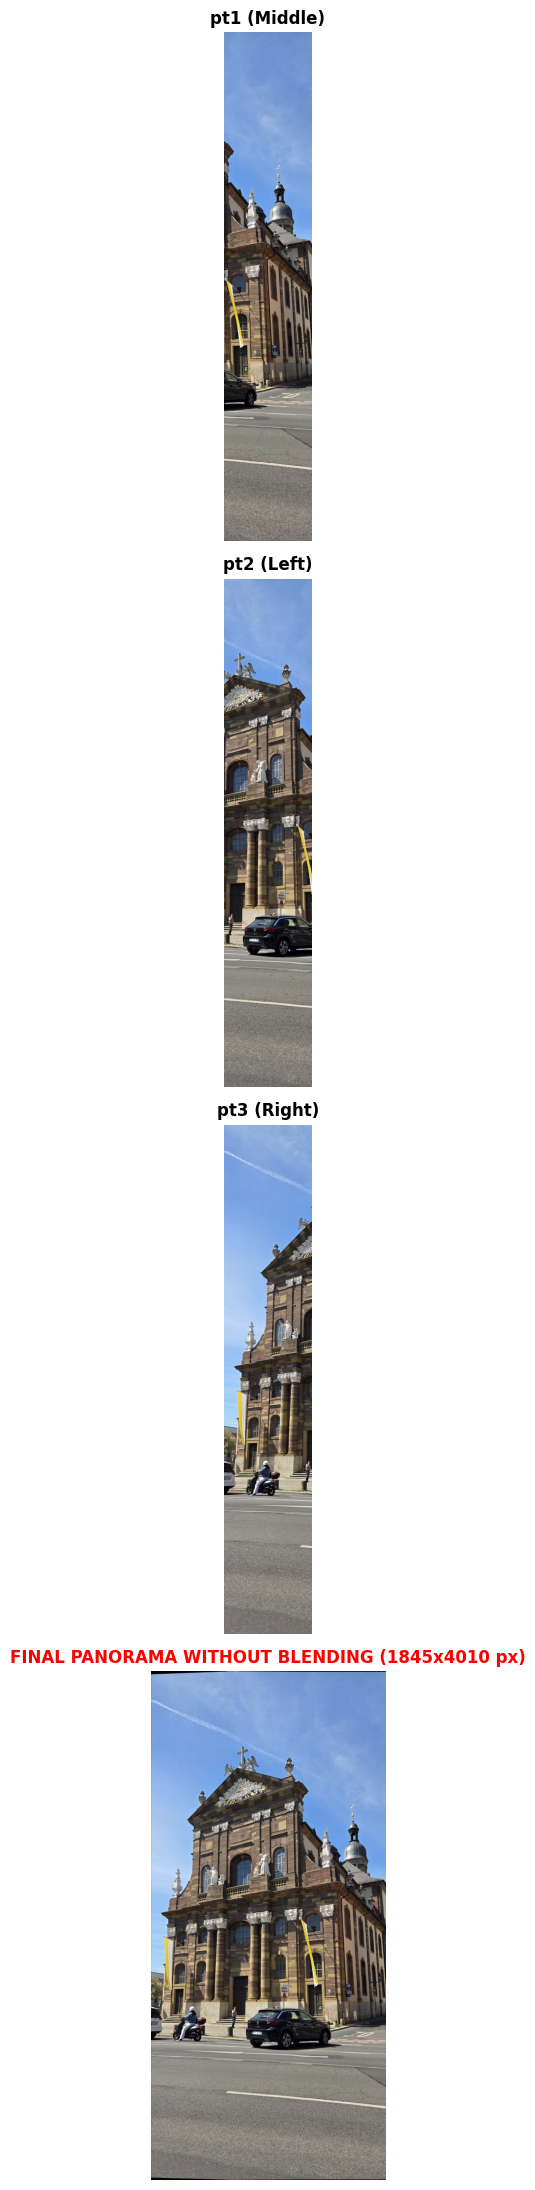

Saved successfully to: C:\Users\USER\OneDrive - GJU\Desktop\4th Year\MI 2\Homeworks\final_stitched_NO_BLENDING.jpg


In [ ]:

# ─────────────────────────────────────────────────────────────────────────────
# 1. HELPERS & VISUALIZATION TOOLS
# ─────────────────────────────────────────────────────────────────────────────
def show(img_bgr, title="", figsize=(18, 6)):
    """Helper to display BGR images correctly in Matplotlib."""
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    plt.title(title, fontsize=14, fontweight="bold", pad=12)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

def resize_to(img, max_w=1200):
    """Resizes large images to prevent memory crashes."""
    h, w = img.shape[:2]
    if w > max_w:
        img = cv2.resize(img, (max_w, int(h * max_w / w)))
    return img

def draw_fancy_keypoints(img, keypoints):
    """Draws keypoints with a color ramp based on scale size and shows orientation."""
    out = img.copy()
    sizes = np.array([k.size for k in keypoints])
    if len(sizes) == 0: return out
    s_min, s_max = sizes.min(), sizes.max() + 1e-6

    for kp in keypoints:
        x, y   = int(kp.pt[0]), int(kp.pt[1])
        radius = max(3, int(kp.size * 1.5))
        t      = (kp.size - s_min) / (s_max - s_min)

        # Color ramp: Blue (small) -> Yellow -> Red (large)
        if t < 0.5:
            r, g, b = int(255 * t * 2), int(200 * t * 2), int(255 * (1 - t * 2))
        else:
            r, g, b = 255, int(200 * (1 - (t - 0.5) * 2)), 0

        cv2.circle(out, (x, y), radius, (b, g, r), -1)
        cv2.circle(out, (x, y), radius, (255, 255, 255), 1)
        cv2.circle(out, (x, y), radius + 2, (0, 0, 0), 1)

        if kp.angle >= 0:
            angle_rad = np.deg2rad(kp.angle)
            ex = int(x + radius * np.cos(angle_rad))
            ey = int(y + radius * np.sin(angle_rad))
            cv2.line(out, (x, y), (ex, ey), (255, 255, 255), 1, cv2.LINE_AA)
    return out

# ─────────────────────────────────────────────────────────────────────────────
# 2. CORE PIPELINE FUNCTIONS (WITHOUT BLENDING)
# ─────────────────────────────────────────────────────────────────────────────
def make_sift():
    return cv2.SIFT_create(nfeatures=2000)

def get_good_matches(des_query, des_train):
    flann = cv2.FlannBasedMatcher(dict(algorithm=1, trees=12), dict(checks=150))
    raw = flann.knnMatch(des_query, des_train, k=2)
    
    # Tightened Lowe's ratio to 0.65 to reject repetitive building textures
    good_matches = []
    for match in raw:
        if len(match) == 2:
            m, n = match
            if m.distance < 0.65 * n.distance:
                good_matches.append(m)
    return good_matches

def compute_homography(kp_query, kp_train, matches):
    pts_query = np.float32([kp_query[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
    pts_train = np.float32([kp_train[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(pts_query, pts_train, cv2.RANSAC, 
                                 ransacReprojThreshold=3.0, 
                                 confidence=0.999, maxIters=5000)
    return H, mask

def stitch_pair_no_blend(img_left, img_right, H):
    """Warps img_right and simply pastes img_left on top (Hard Seam)."""
    h1, w1 = img_left.shape[:2]
    h2, w2 = img_right.shape[:2]

    # Calculate exact corners of warped image
    corners_right = np.float32([[0, 0], [0, h2], [w2, h2], [w2, 0]]).reshape(-1, 1, 2)
    warped_corners = cv2.perspectiveTransform(corners_right, H)
    corners_left = np.float32([[0, 0], [0, h1], [w1, h1], [w1, 0]]).reshape(-1, 1, 2)

    # Find the bounding box of the entire stitched panorama
    all_corners = np.concatenate((corners_left, warped_corners), axis=0)
    [x_min, y_min] = np.int32(all_corners.min(axis=0).ravel() - 0.5)
    [x_max, y_max] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

    # Translation Matrix to shift everything out of negative coordinates
    t_x = -x_min if x_min < 0 else 0
    t_y = -y_min if y_min < 0 else 0
    T = np.array([[1, 0, t_x], [0, 1, t_y], [0, 0, 1]], dtype=np.float32)

    H_trans = T.dot(H)
    nw, nh = x_max - x_min, y_max - y_min

    # 1. Warp the right image onto the new large canvas
    result = cv2.warpPerspective(img_right, H_trans, (nw, nh))
    
    # 2. Overwrite the left side of the canvas directly with the left image (NO BLENDING)
    result[t_y:t_y+h1, t_x:t_x+w1] = img_left

    # 3. Crop black borders
    gray = cv2.cvtColor(result, cv2.COLOR_BGR2GRAY)
    _, th = cv2.threshold(gray, 1, 255, cv2.THRESH_BINARY)
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        x, y, cw, ch = cv2.boundingRect(max(cnts, key=cv2.contourArea))
        result = result[y:y+ch, x:x+cw]
        
    return result


# ─────────────────────────────────────────────────────────────────────────────
# 3. EXECUTION LOGIC WITH FULL STEP-BY-STEP VISUALIZATIONS
# ─────────────────────────────────────────────────────────────────────────────
import os
BASE = "inputs" if os.path.exists("inputs/pt1.jpg") else ("." if os.path.exists("pt1.jpg") else r"C:\Users\USER\OneDrive - GJU\Desktop\4th Year\MI 2\Homeworks")
part1 = resize_to(cv2.imread(BASE + r"\pt1.jpg"))  # Middle Image
part2 = resize_to(cv2.imread(BASE + r"\pt2.jpg"))  # Left Image
part3 = resize_to(cv2.imread(BASE + r"\pt3.jpg"))  # Right Image

if any(p is None for p in [part1, part2, part3]):
    raise FileNotFoundError("Could not load one or more images — check file paths.")

print("── Initializing SIFT ──")
sift = make_sift()

# ==========================================
# PHASE 1: Stitching pt2 (Left) to pt1 (Middle)
# ==========================================
print("\n[PHASE 1] ── STEP 1: Extracting & Visualizing SIFT (pt2 & pt1) ──")
gray1 = cv2.cvtColor(part1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(part2, cv2.COLOR_BGR2GRAY)

kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(gray2, None)

show(draw_fancy_keypoints(part2, kp2), f"SIFT Keypoints on pt2 ({len(kp2)} found)")
show(draw_fancy_keypoints(part1, kp1), f"SIFT Keypoints on pt1 ({len(kp1)} found)")

print("\n[PHASE 1] ── STEP 2: KNN Matches (Lowe's Ratio applied) ──")
matches_21 = get_good_matches(des2, des1) 
print(f"Good matches between pt2 and pt1: {len(matches_21)}")

if len(matches_21) < 4:
    raise RuntimeError("Not enough matches to stitch pt2 and pt1.")

img_knn_21 = cv2.drawMatches(
    part2, kp2, part1, kp1, matches_21[:80], None,
    matchColor=(0, 210, 255), singlePointColor=(180, 80, 0),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
show(img_knn_21, f"Raw KNN Matches pt2 -> pt1 (Top 80 shown)")

print("\n[PHASE 1] ── STEP 3: RANSAC Inliers ──")
H21, mask21 = compute_homography(kp2, kp1, matches_21)

mask_list_21 = mask21.ravel().tolist()
inliers_21 = [matches_21[i] for i in range(len(matches_21)) if mask_list_21[i]]
outliers_count_21 = len(matches_21) - len(inliers_21)

img_ransac_21 = cv2.drawMatches(
    part2, kp2, part1, kp1, inliers_21, None,
    matchColor=(0, 255, 0), singlePointColor=(180, 80, 0),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
show(img_ransac_21, f"RANSAC Inliers pt2 -> pt1 ({len(inliers_21)} verified | {outliers_count_21} rejected)")

print("\n[PHASE 1] ── STEP 4: Stitching pt2 + pt1 (NO BLENDING) ──")
stitch_21 = stitch_pair_no_blend(part1, part2, H21)
show(stitch_21, "Intermediate Panorama (pt2 + pt1) - HARD SEAM")


# ==========================================
# PHASE 2: Stitching pt3 (Right) to Panorama
# ==========================================
print("\n[PHASE 2] ── STEP 5: SIFT on Intermediate Panorama & pt3 ──")
gray_21 = cv2.cvtColor(stitch_21, cv2.COLOR_BGR2GRAY)
gray3 = cv2.cvtColor(part3, cv2.COLOR_BGR2GRAY)

kp_21, des_21 = sift.detectAndCompute(gray_21, None)
kp3, des3 = sift.detectAndCompute(gray3, None)

show(draw_fancy_keypoints(stitch_21, kp_21), f"SIFT Keypoints on Panorama ({len(kp_21)} found)")
show(draw_fancy_keypoints(part3, kp3), f"SIFT Keypoints on pt3 ({len(kp3)} found)")

print("\n[PHASE 2] ── STEP 6: KNN Matches (pt3 -> Panorama) ──")
matches_3_21 = get_good_matches(des3, des_21)
print(f"Good matches between pt3 and panorama: {len(matches_3_21)}")

if len(matches_3_21) < 4:
    raise RuntimeError("Not enough matches to add pt3 to the panorama.")

img_knn_3_21 = cv2.drawMatches(
    part3, kp3, stitch_21, kp_21, matches_3_21[:80], None,
    matchColor=(255, 160, 0), singlePointColor=(180, 80, 0),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
show(img_knn_3_21, "Raw KNN Matches pt3 -> Panorama (Top 80 shown)")

print("\n[PHASE 2] ── STEP 7: RANSAC Inliers (pt3 -> Panorama) ──")
H_3_21, mask_3_21 = compute_homography(kp3, kp_21, matches_3_21)

mask_list_3 = mask_3_21.ravel().tolist()
inliers_3_21 = [matches_3_21[i] for i in range(len(matches_3_21)) if mask_list_3[i]]
outliers_count_3 = len(matches_3_21) - len(inliers_3_21)

img_ransac_3_21 = cv2.drawMatches(
    part3, kp3, stitch_21, kp_21, inliers_3_21, None,
    matchColor=(0, 255, 0), singlePointColor=(180, 80, 0),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
show(img_ransac_3_21, f"RANSAC Inliers pt3 -> Panorama ({len(inliers_3_21)} verified | {outliers_count_3} rejected)")


print("\n[PHASE 2] ── STEP 8: Final Stitch (NO BLENDING) ──")
final_panorama = stitch_pair_no_blend(stitch_21, part3, H_3_21)

# ─────────────────────────────────────────────────────────────────────────────
# 4. FINAL OUTPUT COMPARISON
# ─────────────────────────────────────────────────────────────────────────────
print("\n✓ Pipeline complete! Displaying and saving...")

fig, axes = plt.subplots(4, 1, figsize=(18, 22))
axes[0].imshow(cv2.cvtColor(part1, cv2.COLOR_BGR2RGB)); axes[0].set_title("pt1 (Middle)", fontweight="bold"); axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(part2, cv2.COLOR_BGR2RGB)); axes[1].set_title("pt2 (Left)", fontweight="bold"); axes[1].axis("off")
axes[2].imshow(cv2.cvtColor(part3, cv2.COLOR_BGR2RGB)); axes[2].set_title("pt3 (Right)", fontweight="bold"); axes[2].axis("off")
axes[3].imshow(cv2.cvtColor(final_panorama, cv2.COLOR_BGR2RGB)); axes[3].set_title(f"FINAL PANORAMA WITHOUT BLENDING ({final_panorama.shape[1]}x{final_panorama.shape[0]} px)", color="red", fontweight="bold"); axes[3].axis("off")

plt.tight_layout()
plt.show()

# Save it to your folder
save_path = BASE + r"\final_stitched_NO_BLENDING.jpg"
cv2.imwrite(save_path, final_panorama)
print(f"Saved successfully to: {save_path}")

there was an overlapping in the images, but in both, blending and no blending it was the same output. the following code shows the difference 


[PHASE 1] ── Running Exposure Blending Test ──


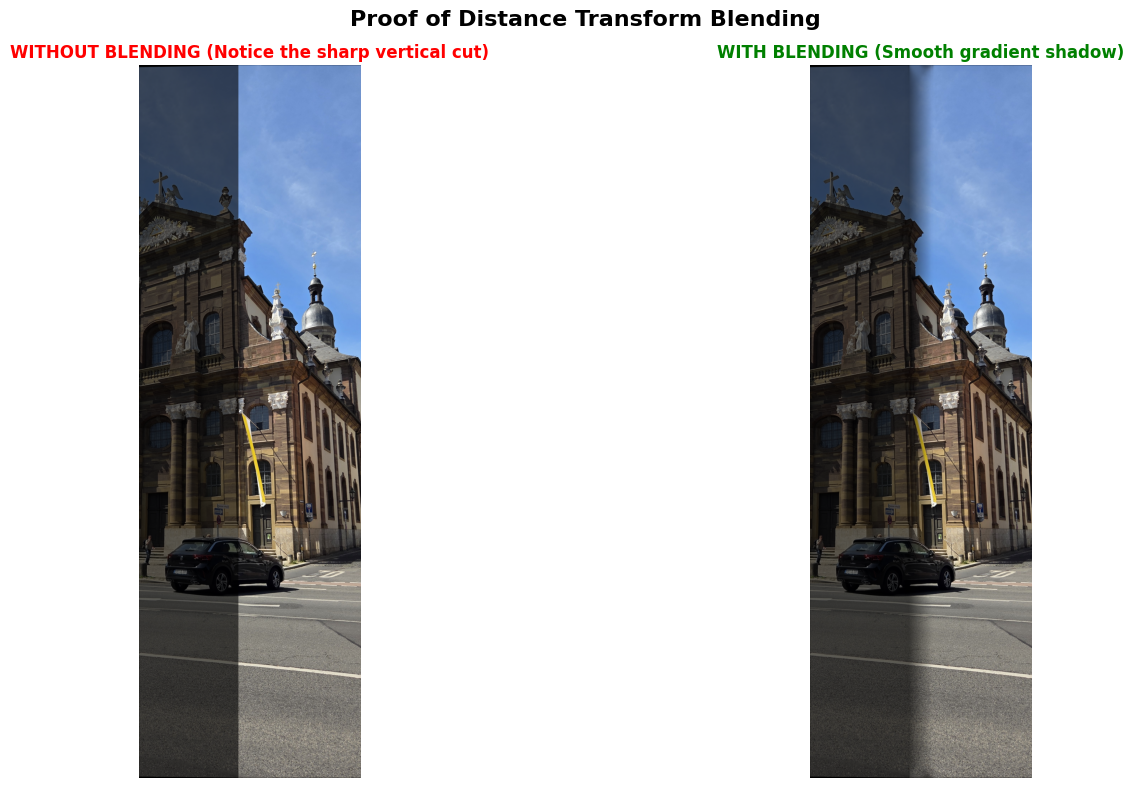


[PHASE 2] ── Stitching Final Clean Panorama ──


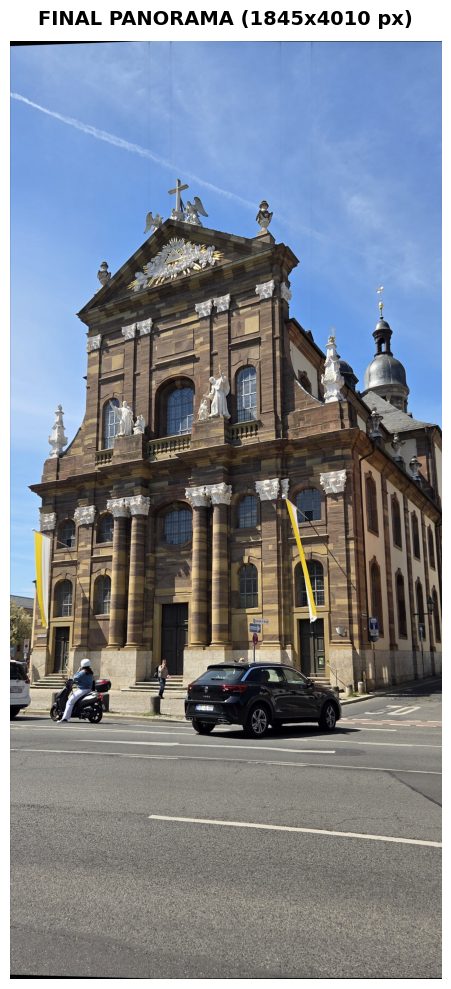

✓ Pipeline complete! Saved successfully to: C:\Users\USER\OneDrive - GJU\Desktop\4th Year\MI 2\Homeworks\FINAL_ULTIMATE_PANORAMA.jpg


In [20]:


# ─────────────────────────────────────────────────────────────────────────────
# 1. HELPERS & VISUALIZATION TOOLS
# ─────────────────────────────────────────────────────────────────────────────
def show(img_bgr, title="", figsize=(18, 6)):
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    plt.title(title, fontsize=14, fontweight="bold", pad=12)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

def resize_to(img, max_w=1200):
    h, w = img.shape[:2]
    if w > max_w:
        img = cv2.resize(img, (max_w, int(h * max_w / w)))
    return img

def draw_fancy_keypoints(img, keypoints):
    out = img.copy()
    sizes = np.array([k.size for k in keypoints])
    if len(sizes) == 0: return out
    s_min, s_max = sizes.min(), sizes.max() + 1e-6

    for kp in keypoints:
        x, y = int(kp.pt[0]), int(kp.pt[1])
        radius = max(3, int(kp.size * 1.5))
        t = (kp.size - s_min) / (s_max - s_min)

        if t < 0.5: r, g, b = int(255 * t * 2), int(200 * t * 2), int(255 * (1 - t * 2))
        else: r, g, b = 255, int(200 * (1 - (t - 0.5) * 2)), 0

        cv2.circle(out, (x, y), radius, (b, g, r), -1)
        cv2.circle(out, (x, y), radius, (255, 255, 255), 1)
        cv2.circle(out, (x, y), radius + 2, (0, 0, 0), 1)

        if kp.angle >= 0:
            angle_rad = np.deg2rad(kp.angle)
            ex = int(x + radius * np.cos(angle_rad))
            ey = int(y + radius * np.sin(angle_rad))
            cv2.line(out, (x, y), (ex, ey), (255, 255, 255), 1, cv2.LINE_AA)
    return out


# ─────────────────────────────────────────────────────────────────────────────
# 2. CORE PIPELINE FUNCTIONS
# ─────────────────────────────────────────────────────────────────────────────
def make_sift():
    return cv2.SIFT_create(nfeatures=2000)

def get_good_matches(des_query, des_train):
    # CRASH PREVENTION: Check if SIFT found features
    if des_query is None or des_train is None or len(des_query) < 2 or len(des_train) < 2:
        print("Warning: Missing or insufficient descriptors for matching.")
        return []
        
    # CRASH PREVENTION: Force float32 format for FLANN
    des_query = np.float32(des_query)
    des_train = np.float32(des_train)

    flann = cv2.FlannBasedMatcher(dict(algorithm=1, trees=12), dict(checks=150))
    raw = flann.knnMatch(des_query, des_train, k=2)
    
    # Lowe's Ratio Test (0.65)
    good_matches = []
    for match in raw:
        if len(match) == 2:
            m, n = match
            if m.distance < 0.65 * n.distance:
                good_matches.append(m)
    return good_matches

def compute_homography(kp_query, kp_train, matches):
    pts_query = np.float32([kp_query[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
    pts_train = np.float32([kp_train[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(pts_query, pts_train, cv2.RANSAC, 
                                 ransacReprojThreshold=3.0, 
                                 confidence=0.999, maxIters=5000)
    return H, mask

def stitch_pair_no_blend(img_left, img_right, H):
    """Warps right image, pastes left image directly on top (Hard Seam)."""
    h1, w1 = img_left.shape[:2]
    h2, w2 = img_right.shape[:2]

    corners_right = np.float32([[0, 0], [0, h2], [w2, h2], [w2, 0]]).reshape(-1, 1, 2)
    warped_corners = cv2.perspectiveTransform(corners_right, H)
    corners_left = np.float32([[0, 0], [0, h1], [w1, h1], [w1, 0]]).reshape(-1, 1, 2)

    all_corners = np.concatenate((corners_left, warped_corners), axis=0)
    [x_min, y_min] = np.int32(all_corners.min(axis=0).ravel() - 0.5)
    [x_max, y_max] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

    t_x, t_y = (-x_min if x_min < 0 else 0), (-y_min if y_min < 0 else 0)
    T = np.array([[1, 0, t_x], [0, 1, t_y], [0, 0, 1]], dtype=np.float32)
    H_trans = T.dot(H)
    nw, nh = x_max - x_min, y_max - y_min

    result = cv2.warpPerspective(img_right, H_trans, (nw, nh))
    result[t_y:t_y+h1, t_x:t_x+w1] = img_left  # Hard Overwrite

    _, th = cv2.threshold(cv2.cvtColor(result, cv2.COLOR_BGR2GRAY), 1, 255, cv2.THRESH_BINARY)
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        x, y, cw, ch = cv2.boundingRect(max(cnts, key=cv2.contourArea))
        result = result[y:y+ch, x:x+cw]
    return result

def blend_pair(img_left, img_right, H):
    """Warps right image and uses Distance Transform Alpha Blending to hide the seam."""
    h1, w1 = img_left.shape[:2]
    h2, w2 = img_right.shape[:2]

    corners_right = np.float32([[0, 0], [0, h2], [w2, h2], [w2, 0]]).reshape(-1, 1, 2)
    warped_corners = cv2.perspectiveTransform(corners_right, H)
    corners_left = np.float32([[0, 0], [0, h1], [w1, h1], [w1, 0]]).reshape(-1, 1, 2)

    all_corners = np.concatenate((corners_left, warped_corners), axis=0)
    [x_min, y_min] = np.int32(all_corners.min(axis=0).ravel() - 0.5)
    [x_max, y_max] = np.int32(all_corners.max(axis=0).ravel() + 0.5)

    t_x, t_y = (-x_min if x_min < 0 else 0), (-y_min if y_min < 0 else 0)
    T = np.array([[1, 0, t_x], [0, 1, t_y], [0, 0, 1]], dtype=np.float32)
    H_trans = T.dot(H)
    nw, nh = x_max - x_min, y_max - y_min

    warped = cv2.warpPerspective(img_right, H_trans, (nw, nh))
    canvas = np.zeros((nh, nw, 3), dtype=np.uint8)
    canvas[t_y:t_y+h1, t_x:t_x+w1] = img_left

    ml = np.zeros((nh, nw), dtype=np.uint8)
    ml[t_y:t_y+h1, t_x:t_x+w1] = 255
    mr = cv2.warpPerspective(np.ones((h2, w2), dtype=np.uint8) * 255, H_trans, (nw, nh))

    dl = cv2.GaussianBlur(cv2.distanceTransform(ml, cv2.DIST_L2, 3).astype(np.float32), (51, 51), 0)
    dr = cv2.GaussianBlur(cv2.distanceTransform(mr, cv2.DIST_L2, 3).astype(np.float32), (51, 51), 0)

    total = dl + dr + 1e-6
    al, ar = (dl / total)[:, :, np.newaxis], (dr / total)[:, :, np.newaxis]

    blended = np.clip(canvas.astype(np.float32)*al + warped.astype(np.float32)*ar, 0, 255).astype(np.uint8)

    _, th = cv2.threshold(cv2.cvtColor(blended, cv2.COLOR_BGR2GRAY), 15, 255, cv2.THRESH_BINARY)
    cnts, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if cnts:
        x, y, cw, ch = cv2.boundingRect(max(cnts, key=cv2.contourArea))
        blended = blended[y:y+ch, x:x+cw]
    return blended


# ─────────────────────────────────────────────────────────────────────────────
# 3. EXECUTION
# ─────────────────────────────────────────────────────────────────────────────
import os
BASE = "inputs" if os.path.exists("inputs/pt1.jpg") else ("." if os.path.exists("pt1.jpg") else r"C:\Users\USER\OneDrive - GJU\Desktop\4th Year\MI 2\Homeworks")
part1 = resize_to(cv2.imread(BASE + r"\pt1.jpg"))  # Middle Image
part2 = resize_to(cv2.imread(BASE + r"\pt2.jpg"))  # Left Image
part3 = resize_to(cv2.imread(BASE + r"\pt3.jpg"))  # Right Image

if any(p is None for p in [part1, part2, part3]):
    raise FileNotFoundError("Could not load one or more images — check file paths.")

sift = make_sift()
gray1 = cv2.cvtColor(part1, cv2.COLOR_BGR2GRAY)
kp1, des1 = sift.detectAndCompute(gray1, None)


# ==========================================
# PHASE 1: THE BLENDING TEST (For your report)
# ==========================================
print("\n[PHASE 1] ── Running Exposure Blending Test ──")
# Artificially darken the left image to force a harsh seam
part2_dark = cv2.convertScaleAbs(part2, alpha=0.4, beta=0) 
gray2_dark = cv2.cvtColor(part2_dark, cv2.COLOR_BGR2GRAY)

kp2_dark, des2_dark = sift.detectAndCompute(gray2_dark, None)
matches_test = get_good_matches(des2_dark, des1)
H_test, _ = compute_homography(kp2_dark, kp1, matches_test)

# Test 1: Hard Seam
test_no_blend = stitch_pair_no_blend(part1, part2_dark, H_test)
# Test 2: Alpha Gradient
test_with_blend = blend_pair(part1, part2_dark, H_test)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
axes[0].imshow(cv2.cvtColor(test_no_blend, cv2.COLOR_BGR2RGB))
axes[0].set_title("WITHOUT BLENDING (Notice the sharp vertical cut)", fontweight="bold", color="red")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(test_with_blend, cv2.COLOR_BGR2RGB))
axes[1].set_title("WITH BLENDING (Smooth gradient shadow)", fontweight="bold", color="green")
axes[1].axis("off")

plt.suptitle("Proof of Distance Transform Blending", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()


# ==========================================
# PHASE 2: BUILDING THE FULL PANORAMA
# ==========================================
print("\n[PHASE 2] ── Stitching Final Clean Panorama ──")
gray2 = cv2.cvtColor(part2, cv2.COLOR_BGR2GRAY)
kp2, des2 = sift.detectAndCompute(gray2, None)

# Step A: pt2 -> pt1
matches_21 = get_good_matches(des2, des1) 
if len(matches_21) < 4: raise RuntimeError("Not enough matches to stitch pt2 and pt1.")
H21, _ = compute_homography(kp2, kp1, matches_21)
stitch_21 = blend_pair(part1, part2, H21)

# Step B: pt3 -> Panorama
gray_21 = cv2.cvtColor(stitch_21, cv2.COLOR_BGR2GRAY)
gray3 = cv2.cvtColor(part3, cv2.COLOR_BGR2GRAY)

kp_21, des_21 = sift.detectAndCompute(gray_21, None)
kp3, des3 = sift.detectAndCompute(gray3, None)

matches_3_21 = get_good_matches(des3, des_21)
if len(matches_3_21) < 4: raise RuntimeError("Not enough matches to add pt3 to the panorama.")
H_3_21, _ = compute_homography(kp3, kp_21, matches_3_21)

final_panorama = blend_pair(stitch_21, part3, H_3_21)

show(final_panorama, f"FINAL PANORAMA ({final_panorama.shape[1]}x{final_panorama.shape[0]} px)", figsize=(18, 10))

# Save it to your folder
save_path = BASE + r"\FINAL_ULTIMATE_PANORAMA.jpg"
cv2.imwrite(save_path, final_panorama)
print(f"✓ Pipeline complete! Saved successfully to: {save_path}")